In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
import zipfile, io, requests

# Visualization defaults
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [ ]:
# Download Online Retail Dataset directly from UCI
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
r = requests.get(url)
z = zipfile.ZipFile(io.BytesIO(r.content))
df_raw = pd.read_excel(z.open('Online Retail.xlsx')) #df--->Dataframe

print("Dataset Shape:", df_raw.shape)
print("\nDataset Info:")
df_raw.info()
print("\nDescriptive Statistics:\n", df_raw.describe())

Dataset Shape: (541909, 8)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Descriptive Statistics:
             Quantity                    InvoiceDate      UnitPrice  \
count  541909.000000                         541909  541909.000000   
mean        9.552250  2011-07-04 13:34:57.156386048       4.611114   
min    -80995.000000          

In [ ]:
df = df_raw.copy()

# Remove missing CustomerIDs
df.dropna(subset=['CustomerID'], inplace=True)
df['CustomerID'] = df['CustomerID'].astype(int)

# Filter out cancelled orders and invalid prices/quantities
df['IsCancelled'] = df['InvoiceNo'].astype(str).str.startswith('C')
df_clean = df[(~df['IsCancelled']) & (df['Quantity'] > 0) & (df['UnitPrice'] > 0)].copy()

# Drop duplicates
df_clean.drop_duplicates(inplace=True)

# Feature Engineering
df_clean['TotalSales'] = df_clean['Quantity'] * df_clean['UnitPrice']
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M')
df_clean['DayOfWeek'] = df_clean['InvoiceDate'].dt.day_name()
df_clean['Hour'] = df_clean['InvoiceDate'].dt.hour

print("Cleaned Dataset Shape:", df_clean.shape)

Cleaned Dataset Shape: (392692, 13)


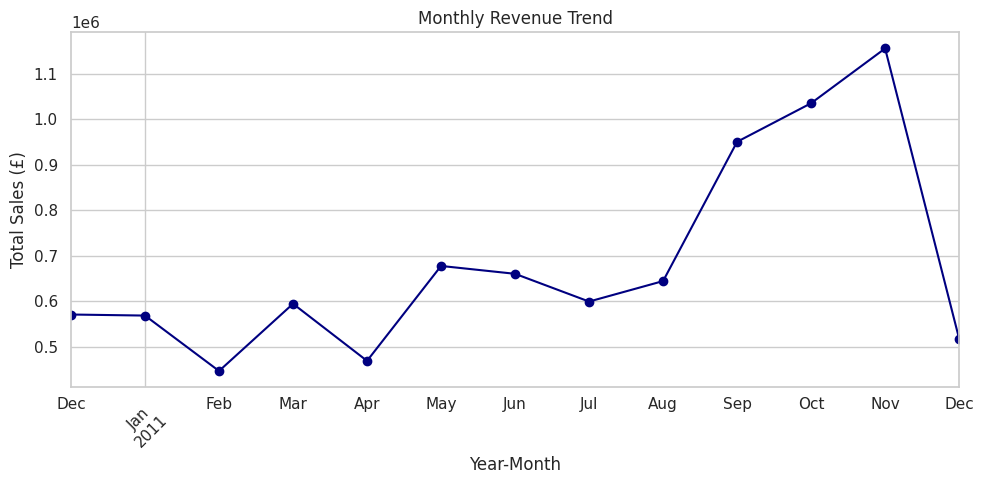

In [ ]:
# Time-Series Plot: Monthly Total Revenue
plt.figure(figsize=(10, 5))
monthly_sales = df_clean.groupby('YearMonth')['TotalSales'].sum()
monthly_sales.plot(kind='line', marker='o', color='navy')
plt.title('Monthly Revenue Trend')
plt.ylabel('Total Sales (£)')
plt.xlabel('Year-Month')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

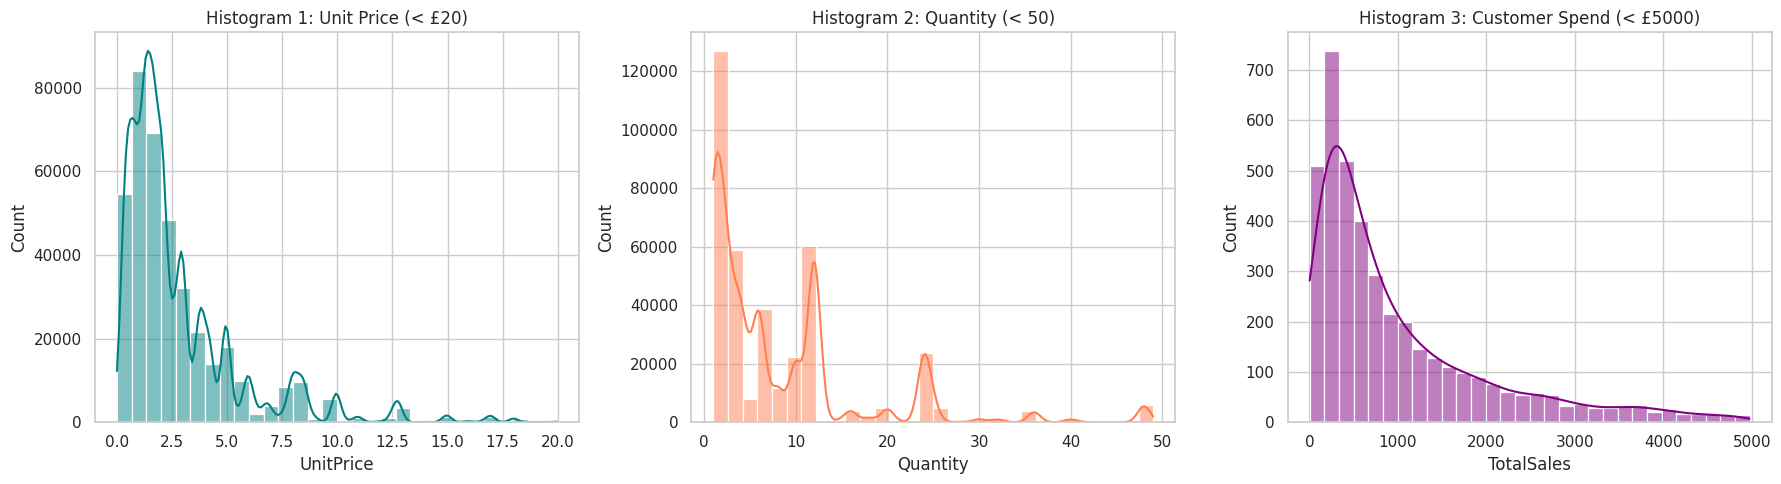

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histogram 1: Unit Price
sns.histplot(df_clean['UnitPrice'][df_clean['UnitPrice'] < 20], bins=30, ax=axes[0], kde=True, color='teal')
axes[0].set_title('Histogram 1: Unit Price (< £20)')

# Histogram 2: Quantity
sns.histplot(df_clean['Quantity'][df_clean['Quantity'] < 50], bins=30, ax=axes[1], kde=True, color='coral')
axes[1].set_title('Histogram 2: Quantity (< 50)')

# Histogram 3: Customer Total Spend
customer_spend = df_clean.groupby('CustomerID')['TotalSales'].sum()
sns.histplot(customer_spend[customer_spend < 5000], bins=30, ax=axes[2], kde=True, color='purple')
axes[2].set_title('Histogram 3: Customer Spend (< £5000)')

plt.tight_layout()
plt.show()

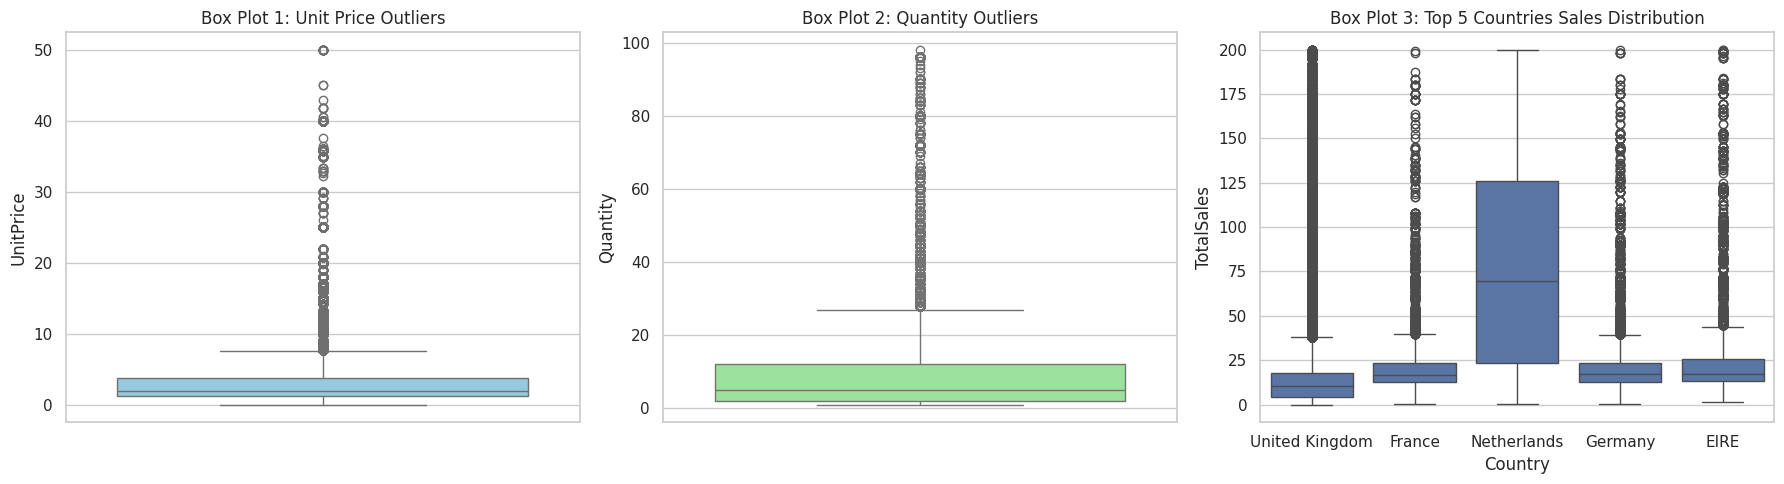

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Box Plot 1: Unit Price
sns.boxplot(y=df_clean['UnitPrice'][df_clean['UnitPrice'] < 50], ax=axes[0], color='skyblue')
axes[0].set_title('Box Plot 1: Unit Price Outliers')

# Box Plot 2: Quantity
sns.boxplot(y=df_clean['Quantity'][df_clean['Quantity'] < 100], ax=axes[1], color='lightgreen')
axes[1].set_title('Box Plot 2: Quantity Outliers')

# Box Plot 3: Sales Distribution Across Top 5 Countries
top_5_countries = df_clean.groupby('Country')['TotalSales'].sum().nlargest(5).index
sns.boxplot(x='Country', y='TotalSales', data=df_clean[(df_clean['Country'].isin(top_5_countries)) & (df_clean['TotalSales'] < 200)], ax=axes[2])
axes[2].set_title('Box Plot 3: Top 5 Countries Sales Distribution')

plt.tight_layout()
plt.show()

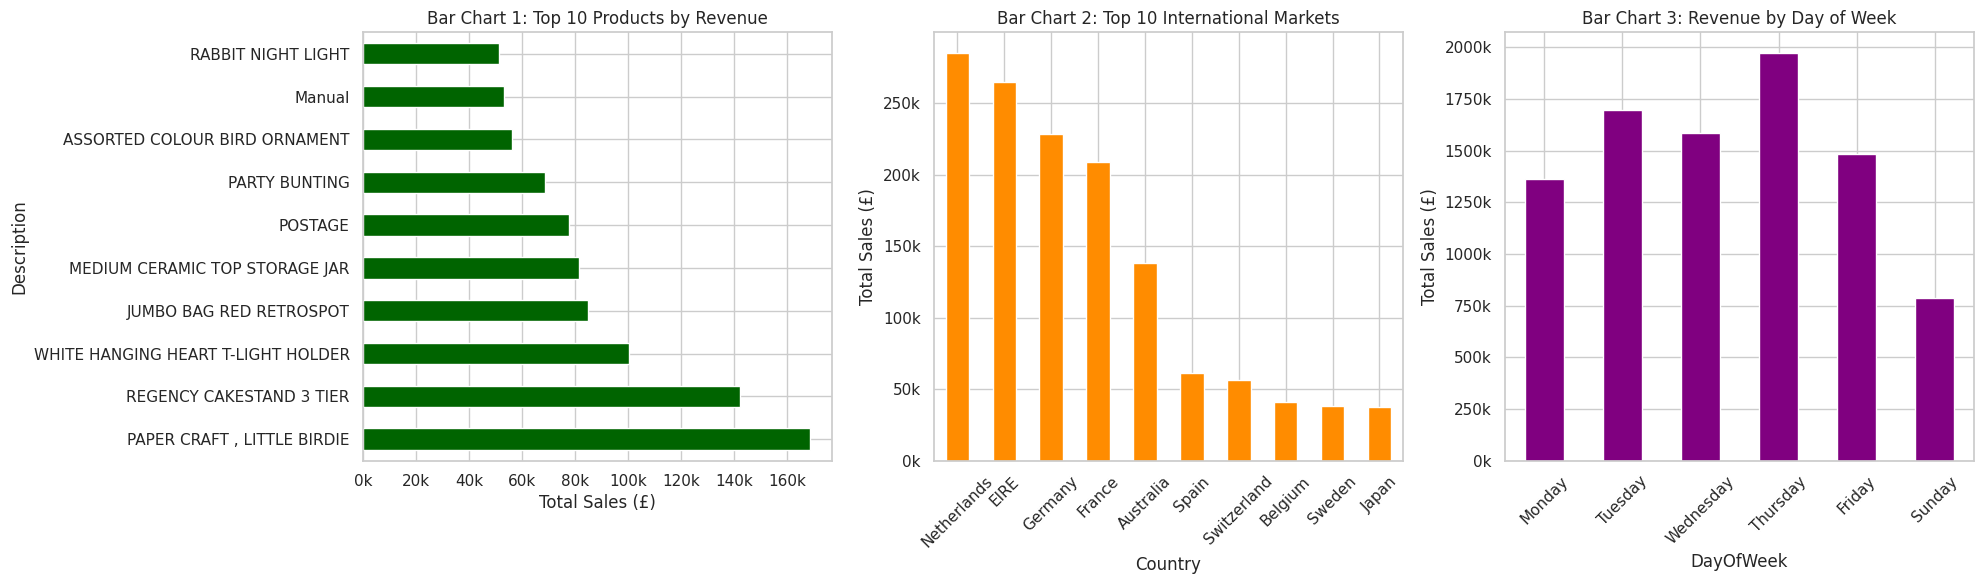

In [ ]:
import matplotlib.ticker as ticker

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Helper function to format large values into 'k' (e.g., 150000 -> 150k)
k_formatter = ticker.FuncFormatter(lambda x, pos: f'{int(x/1000)}k')

# Bar Chart 1: Top 10 Products by Revenue
df_clean.groupby('Description')['TotalSales'].sum().nlargest(10).plot(kind='barh', ax=axes[0], color='darkgreen')
axes[0].set_title('Bar Chart 1: Top 10 Products by Revenue')
axes[0].set_xlabel('Total Sales (£)')
axes[0].xaxis.set_major_formatter(k_formatter)  # Fixes overlapping numbers on x-axis

# Bar Chart 2: Top International Markets (Excl. UK)
df_clean[df_clean['Country'] != 'United Kingdom'].groupby('Country')['TotalSales'].sum().nlargest(10).plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('Bar Chart 2: Top 10 International Markets')
axes[1].set_ylabel('Total Sales (£)')
axes[1].yaxis.set_major_formatter(k_formatter)  # Formats y-axis nicely
axes[1].tick_params(axis='x', rotation=45)       # Rotates country names so they don't overlap

# Bar Chart 3: Day of Week Sales
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Sunday']
df_clean.groupby('DayOfWeek')['TotalSales'].sum().reindex(day_order).plot(kind='bar', ax=axes[2], color='purple')
axes[2].set_title('Bar Chart 3: Revenue by Day of Week')
axes[2].set_ylabel('Total Sales (£)')
axes[2].yaxis.set_major_formatter(k_formatter)  # Formats y-axis nicely
axes[2].tick_params(axis='x', rotation=45)       # Rotates day names cleanly

plt.tight_layout()
plt.show()

/tmp/ipykernel_8714/422221349.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Hour', data=df_clean, ax=axes[0], palette='viridis')
/tmp/ipykernel_8714/422221349.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='IsCancelled', data=df, ax=axes[1], palette='Set2')
/tmp/ipykernel_8714/422221349.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Completed', 'Cancelled'])


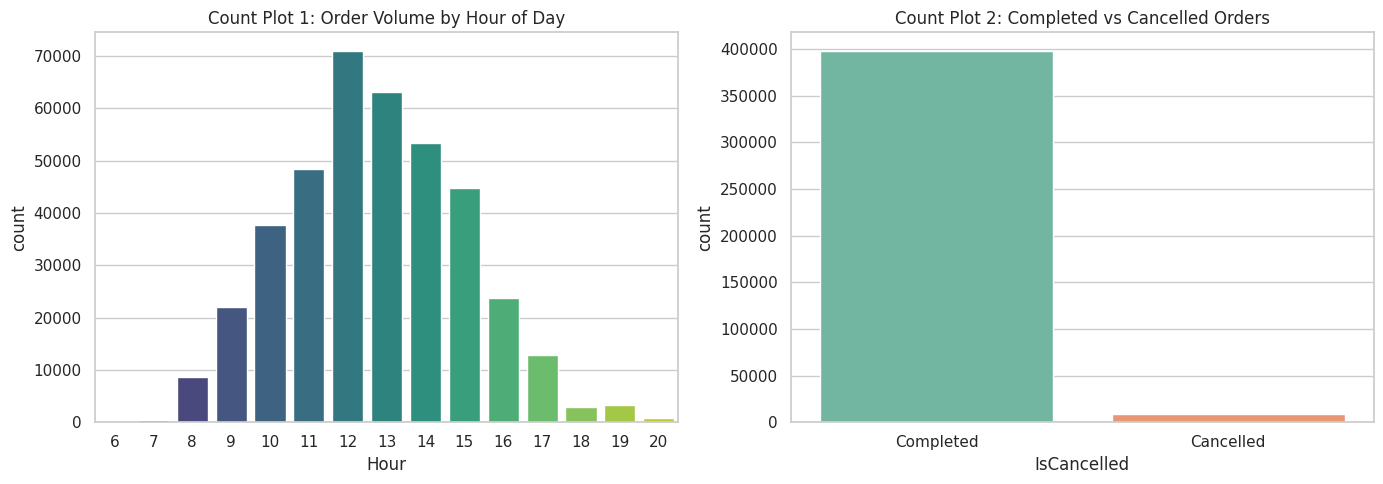

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count Plot 1: Hourly Order Volume
sns.countplot(x='Hour', data=df_clean, ax=axes[0], palette='viridis')
axes[0].set_title('Count Plot 1: Order Volume by Hour of Day')

# Count Plot 2: Cancellation vs Completed
sns.countplot(x='IsCancelled', data=df, ax=axes[1], palette='Set2')
axes[1].set_title('Count Plot 2: Completed vs Cancelled Orders')
axes[1].set_xticklabels(['Completed', 'Cancelled'])

plt.tight_layout()
plt.show()

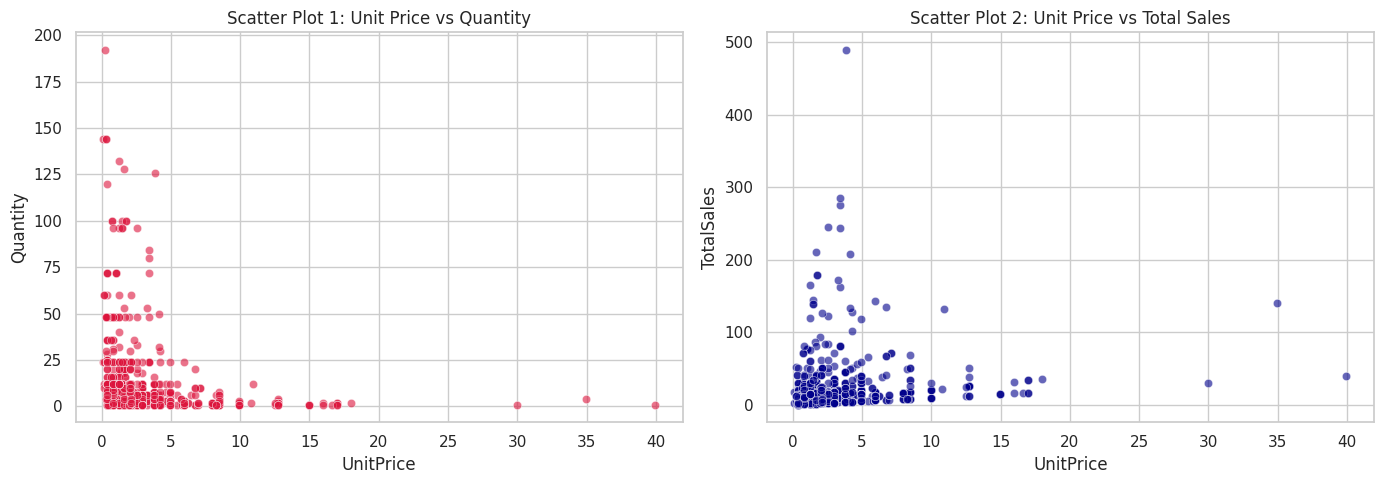

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sample_df = df_clean[(df_clean['Quantity'] < 200) & (df_clean['UnitPrice'] < 100)].sample(1000, random_state=42)

# Scatter Plot 1: Unit Price vs Quantity
sns.scatterplot(x='UnitPrice', y='Quantity', data=sample_df, alpha=0.6, ax=axes[0], color='crimson')
axes[0].set_title('Scatter Plot 1: Unit Price vs Quantity')

# Scatter Plot 2: Unit Price vs Total Sales
sns.scatterplot(x='UnitPrice', y='TotalSales', data=sample_df, alpha=0.6, ax=axes[1], color='darkblue')
axes[1].set_title('Scatter Plot 2: Unit Price vs Total Sales')

plt.tight_layout()
plt.show()

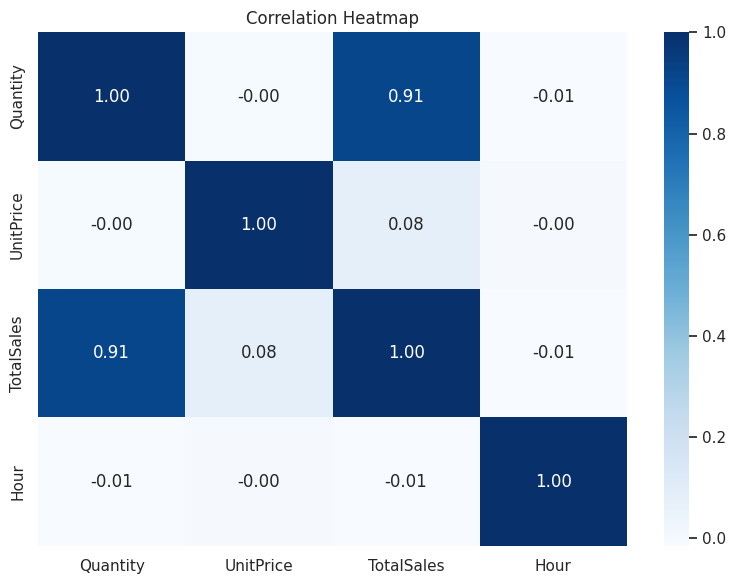

In [ ]:
plt.figure(figsize=(8, 6))
numeric_df = df_clean[['Quantity', 'UnitPrice', 'TotalSales', 'Hour']].corr()
sns.heatmap(numeric_df, annot=True, cmap='Blues', fmt=".2f")
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

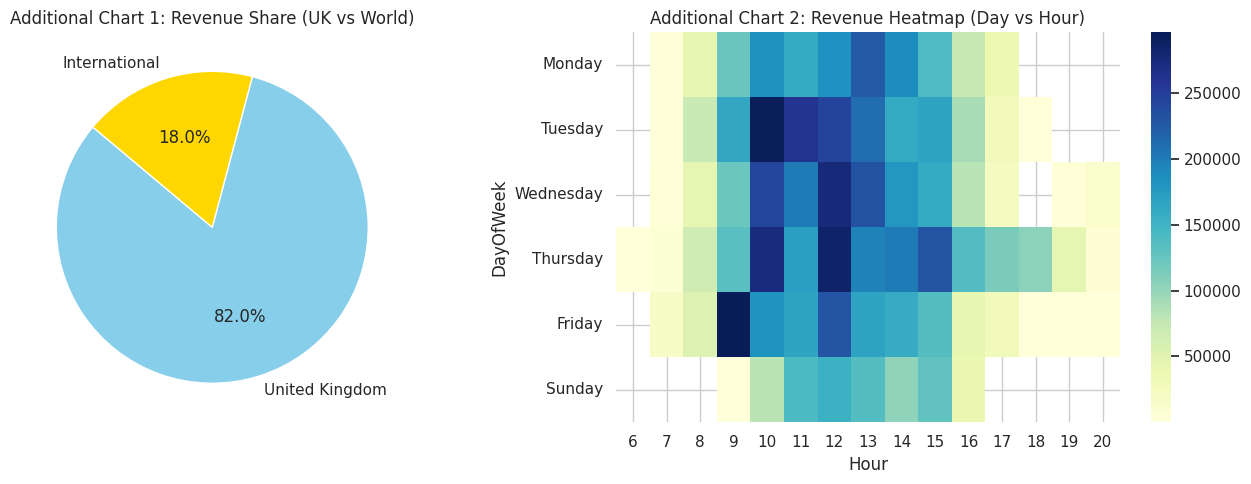

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Additional Chart 1: Pie Chart (UK vs World Revenue)
uk_vs_world = pd.Series({
    'United Kingdom': df_clean[df_clean['Country'] == 'United Kingdom']['TotalSales'].sum(),
    'International': df_clean[df_clean['Country'] != 'United Kingdom']['TotalSales'].sum()
})
uk_vs_world.plot(kind='pie', autopct='%1.1f%%', ax=axes[0], colors=['skyblue', 'gold'], startangle=140)
axes[0].set_title('Additional Chart 1: Revenue Share (UK vs World)')
axes[0].set_ylabel('')

# Additional Chart 2: Hourly Sales Heatmap across Days
pv = df_clean.pivot_table(index='DayOfWeek', columns='Hour', values='TotalSales', aggfunc='sum').reindex(day_order)
sns.heatmap(pv, cmap='YlGnBu', ax=axes[1])
axes[1].set_title('Additional Chart 2: Revenue Heatmap (Day vs Hour)')

plt.tight_layout()
plt.show()